# Bonus 3 — Reproduction sur un second jeu : Online Retail (segmentation RFM)

Jeu *Online Retail* (UCI) : ≈ 541 900 lignes de transactions d'un e-commerçant britannique (déc. 2010 → déc. 2011).
On construit pour chaque client les indicateurs **RFM** :
- **R**écence : jours depuis le dernier achat ;
- **F**réquence : nombre de factures distinctes ;
- **M**ontant : chiffre d'affaires total.

Puis on applique la même démarche : nettoyage → transformation → K-means (coude + silhouette) → validation (DB, stabilité) → profilage, et on compare à la segmentation RFM « par scores » classique.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from src.config import SEED, ROOT, FIGURES, RESULTS
from src.metrics import elbow_k, pairwise_ari

sns.set_theme(style="whitegrid", palette="tab10"); plt.rcParams["figure.dpi"] = 110
def save(fig, name): fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

df = pd.read_csv(ROOT / "data" / "online-retail.csv.gz", encoding="latin1")
print(df.shape); df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 1. Nettoyage

In [2]:
n0 = len(df)
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
steps = {}
df = df.dropna(subset=["CustomerID"]); steps["sans CustomerID"] = n0 - len(df); n1 = len(df)
df = df[~df["InvoiceNo"].str.startswith("C")]; steps["factures d'annulation (C…)"] = n1 - len(df); n2 = len(df)
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]; steps["quantité/prix ≤ 0"] = n2 - len(df); n3 = len(df)
df = df.drop_duplicates(); steps["doublons"] = n3 - len(df)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")
df["Montant"] = df["Quantity"] * df["UnitPrice"]
print(pd.Series(steps, name="lignes supprimées")); print("Lignes restantes :", len(df), "| clients :", df["CustomerID"].nunique())

sans CustomerID               135080
factures d'annulation (C…)      8905
quantité/prix ≤ 0                 40
doublons                        5192
Name: lignes supprimées, dtype: int64
Lignes restantes : 392692 | clients : 4338


## 2. Construction des variables RFM
Date de référence = lendemain de la dernière transaction.

In [3]:
ref = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(Recence=("InvoiceDate", lambda s: (ref - s.max()).days),
                                   Frequence=("InvoiceNo", "nunique"), Montant=("Montant", "sum"))
rfm.describe().round(1)

,Recence,Frequence,Montant
count,4338.0,4338.0,4338.0
mean,92.5,4.3,2048.7
std,100.0,7.7,8985.2
min,1.0,1.0,3.8
25%,18.0,1.0,306.5
50%,51.0,2.0,668.6
75%,142.0,5.0,1660.6
max,374.0,209.0,280206.0


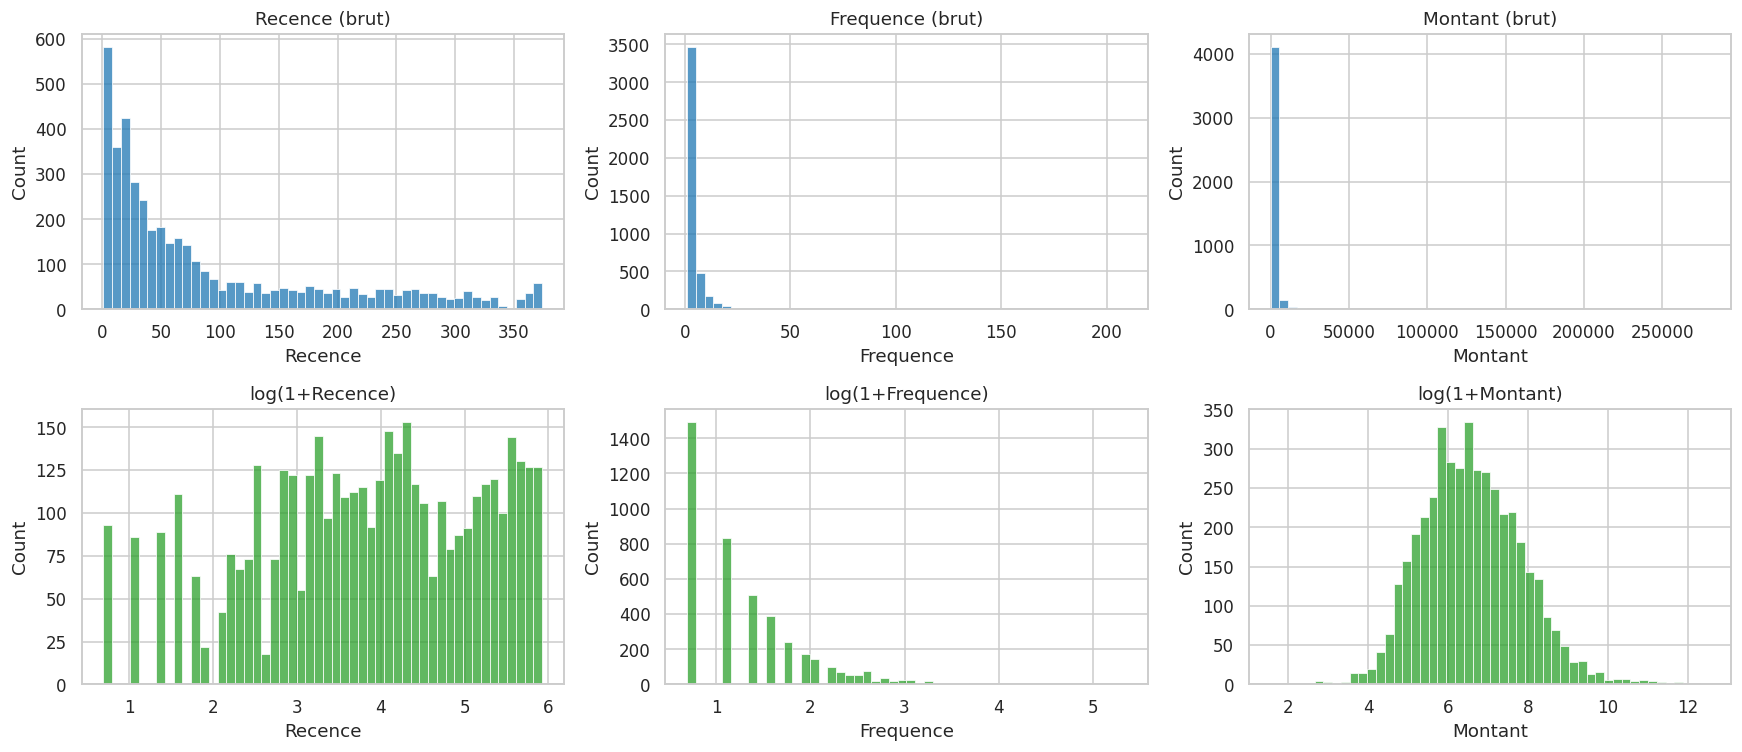

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for j, c in enumerate(rfm.columns):
    sns.histplot(rfm[c], bins=50, ax=axes[0, j]); axes[0, j].set_title(f"{c} (brut)")
    sns.histplot(np.log1p(rfm[c]), bins=50, ax=axes[1, j], color="C2"); axes[1, j].set_title(f"log(1+{c})")
fig.tight_layout(); save(fig, "b3_rfm_distributions")

Distributions **très asymétriques** (quelques gros clients, grossistes) : transformation $\log(1+x)$ puis standardisation, comme pour `campaign` dans le projet principal.

Coude : 5


,k,inertie,silhouette,davies_bouldin
0,2,6483.589,0.433,0.892
1,3,4869.489,0.337,1.048
2,4,3939.049,0.338,1.009
3,5,3296.709,0.316,0.988
4,6,2855.764,0.312,1.021
5,7,2548.820,0.309,0.982
6,8,2336.341,0.303,0.989
7,9,2156.006,0.281,1.019
8,10,2005.746,0.277,1.027


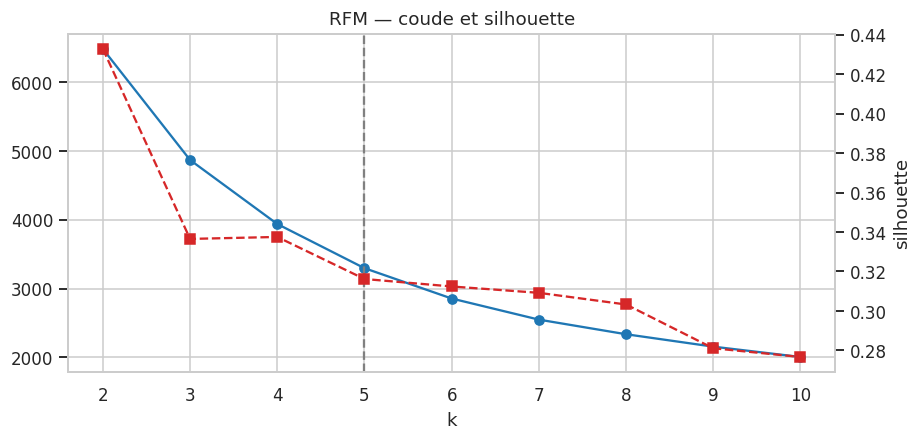

In [5]:
Z = StandardScaler().fit_transform(np.log1p(rfm))
rows = []
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
    rows.append({"k": k, "inertie": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                 "davies_bouldin": davies_bouldin_score(Z, km.labels_)})
kdf = pd.DataFrame(rows)
k_el = elbow_k(kdf["k"], kdf["inertie"])
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(kdf["k"], kdf["inertie"], "o-"); ax1.axvline(k_el, ls="--", color="grey"); ax1.set_xlabel("k")
ax2 = ax1.twinx(); ax2.plot(kdf["k"], kdf["silhouette"], "s--", color="C3"); ax2.grid(False); ax2.set_ylabel("silhouette")
ax1.set_title("RFM — coude et silhouette"); save(fig, "b3_rfm_coude")
print("Coude :", k_el); kdf.round(3)

## 3. Choix de k, stabilité et profilage

In [6]:
K = 4 if k_el in (3, 4, 5) else k_el      # 4 segments : lisible pour un plan d'action CRM
labs = [KMeans(K, n_init=1, random_state=s).fit_predict(Z) for s in range(20)]
rng = np.random.default_rng(SEED)
ref_km = KMeans(K, n_init=10, random_state=SEED).fit(Z)
boot = [adjusted_rand_score(ref_km.labels_, KMeans(K, n_init=3, random_state=b).fit(Z[bi]).predict(Z))
        for b, bi in enumerate(rng.integers(0, len(Z), (20, len(Z))))]
print(f"k = {K} | ARI 20 graines : {pairwise_ari(labs).mean():.3f} | ARI bootstrap : {np.mean(boot):.3f} ± {np.std(boot):.3f}")
rfm["cluster"] = ref_km.labels_
prof = rfm.groupby("cluster").agg(clients=("Recence", "size"), Recence=("Recence", "median"),
                                  Frequence=("Frequence", "median"), Montant=("Montant", "median"),
                                  CA_total=("Montant", "sum"))
prof["% clients"] = 100 * prof["clients"] / prof["clients"].sum()
prof["% CA"] = 100 * prof["CA_total"] / prof["CA_total"].sum()
prof = prof.sort_values("Montant", ascending=False)
prof.round(1)

k = 4 | ARI 20 graines : 0.929 | ARI bootstrap : 0.911 ± 0.044


,clients,Recence,Frequence,Montant,CA_total,% clients,% CA
cluster,,,,,,,
0,713,8.0,10.0,3722.8,5766757.1,16.4,64.9
3,1166,57.0,4.0,1345.2,2100873.0,26.9,23.6
2,837,17.0,2.0,480.3,466479.0,19.3,5.2
1,1622,174.5,1.0,296.1,553099.8,37.4,6.2


In [7]:
# Nommage à partir des médianes : M max → Champions ; R max → Perdus ;
# parmi les deux restants, le plus récent = Nouveaux clients, l'autre = Réguliers à relancer
champ = prof["Montant"].idxmax(); perdu = prof["Recence"].idxmax()
rest = [c for c in prof.index if c not in (champ, perdu)]
nouv, regu = sorted(rest, key=lambda c: prof.loc[c, "Recence"])
noms = {champ: "Champions", perdu: "Perdus / occasionnels", nouv: "Nouveaux clients", regu: "Réguliers à relancer"}
rfm["segment"] = rfm["cluster"].map(noms)
prof.index = prof.index.map(noms)
prof.to_csv(RESULTS / "b3_rfm_profils.csv")
prof.round(1)

,clients,Recence,Frequence,Montant,CA_total,% clients,% CA
cluster,,,,,,,
Champions,713,8.0,10.0,3722.8,5766757.1,16.4,64.9
Réguliers à relancer,1166,57.0,4.0,1345.2,2100873.0,26.9,23.6
Nouveaux clients,837,17.0,2.0,480.3,466479.0,19.3,5.2
Perdus / occasionnels,1622,174.5,1.0,296.1,553099.8,37.4,6.2


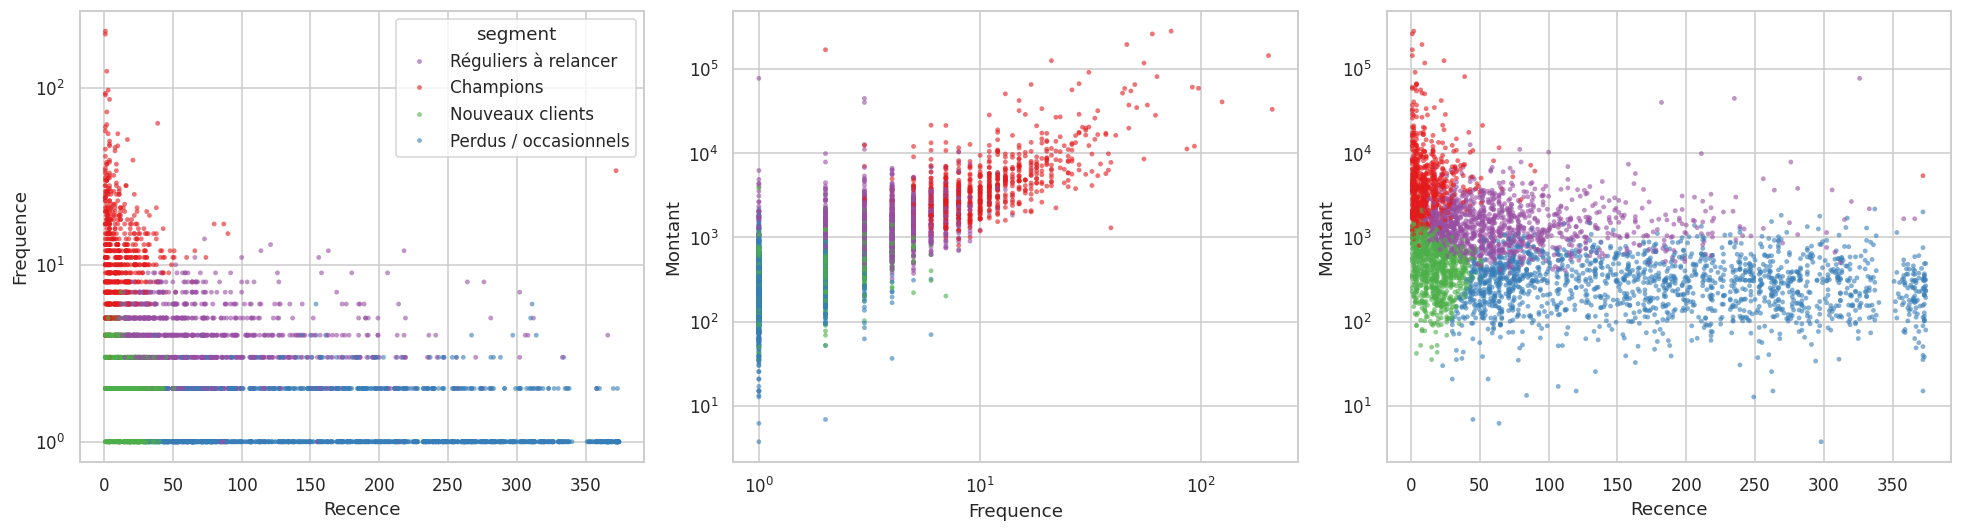

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pal = dict(zip(noms.values(), sns.color_palette("Set1", len(noms))))
for ax, (a, b) in zip(axes, [("Recence", "Frequence"), ("Frequence", "Montant"), ("Recence", "Montant")]):
    sns.scatterplot(data=rfm, x=a, y=b, hue="segment", palette=pal, s=10, alpha=.6, ax=ax, linewidth=0,
                    legend=(a == "Recence" and b == "Frequence"))
    ax.set_xscale("log" if a != "Recence" else "linear"); ax.set_yscale("log")
fig.tight_layout(); save(fig, "b3_rfm_scatter")

## 4. Comparaison avec la segmentation RFM « par scores »
Méthode marketing classique : quintiles de R, F, M (scores 1-5), puis règles. On la compare au clustering avec l'ARI.

In [9]:
rfm["R_score"] = pd.qcut(rfm["Recence"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_score"] = pd.qcut(rfm["Frequence"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_score"] = pd.qcut(rfm["Montant"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
def regle(r):
    if r.R_score >= 4 and r.F_score >= 4: return "Champions"
    if r.R_score >= 4 and r.F_score <= 2: return "Nouveaux clients"
    if r.R_score <= 2 and r.F_score <= 2: return "Perdus / occasionnels"
    return "Réguliers à relancer"
rfm["segment_scores"] = rfm.apply(regle, axis=1)
print("ARI clustering vs règles RFM :", round(adjusted_rand_score(rfm["segment"], rfm["segment_scores"]), 3))
pd.crosstab(rfm["segment"], rfm["segment_scores"])

ARI clustering vs règles RFM : 0.316


segment_scores,Champions,Nouveaux clients,Perdus / occasionnels,Réguliers à relancer
segment,,,,
Champions,675,0,0,38
Nouveaux clients,184,297,0,356
Perdus / occasionnels,0,12,1011,599
Réguliers à relancer,280,10,54,822


**Conclusions du bonus RFM**
- La démarche du projet se **transpose directement** : transformation log + standardisation, coude + silhouette, stabilité, profilage.
- Sur RFM les clusters sont **plus nets** que sur Bank Marketing (silhouette 0,34 à k = 4 contre 0,19) et **plus stables** (ARI bootstrap 0,91) : 3 variables continues fortement structurées, sans qualitatives.
- Le coude indique k = 5 mais la silhouette est quasi identique à k = 4 (0,338) : on retient **4 segments**, plus lisibles pour un plan CRM.
- **Champions** : 16 % des clients, **65 % du chiffre d'affaires** (récence médiane 8 j, 10 factures) — principe de Pareto. **Réguliers à relancer** : 27 % des clients, 24 % du CA, dernier achat il y a ~2 mois. **Nouveaux clients** : récents (17 j) mais 2 factures seulement. **Perdus / occasionnels** : 37 % des clients pour 6 % du CA.
- Clustering et règles par quintiles sont **cohérents mais pas identiques** (ARI ≈ 0,32) : les règles imposent des seuils arbitraires, le clustering découvre les frontières dans les données.
- Actions : programme VIP pour les Champions, relance personnalisée avant décrochage pour les Réguliers, parcours d'onboarding / second achat pour les Nouveaux, canaux à très bas coût pour les Perdus.